# Entrega 2 — Base 2: Clasificación (Hotel Booking)
## Naive Bayes, Red Bayesiana, Máquina de Soporte Vectorial y Red Neuronal Artificial

**Inteligencia Computacional II**

**Objetivo:** ampliar el experimento de la Entrega 1 (Árbol de Decisión, Random Forest y KNN) con las familias de modelos de la Entrega 2 y **comparar todos** sobre exactamente la misma partición de datos, prediciendo si una reserva se cancela (`is_canceled`).

| Familia | Modelo | Idea central |
|---|---|---|
| Bayesiana | **Naive Bayes** (`GaussianNB` y `CategoricalNB`) | Aplica el teorema de Bayes **suponiendo** que todos los atributos son independientes entre sí dentro de cada clase (independencia "ingenua", casi nunca cierta) |
| Bayesiana | **Red Bayesiana** (librería `pgmpy`) | En vez de suponer independencia, **aprende de los datos qué atributos dependen de cuáles** y lo representa como un grafo |
| Máquinas de Soporte Vectorial | `LinearSVC` / `SVC` (kernel RBF) | Busca la frontera que separa las clases con el **mayor margen** posible |
| Redes Neuronales Artificiales | `MLPClassifier` | Capas de neuronas conectadas; se comparan **3 redes: una suave y dos que incrementan neuronas y capas ocultas** |

**Metodología (idéntica a la Entrega 1, para que la comparación sea justa):**

- Hold-Out estratificado con ratio **configurable** (`HOLDOUT_TEST_SIZE`), por defecto 70/30, `random_state=42` → **misma partición** de la Entrega 1.
- Hiperparámetros y **umbral de decisión** elegidos con validación cruzada de 5 folds **dentro de TRAIN** (umbral que maximiza F1 sobre predicciones *out-of-fold*, igual que en la Entrega 1). TEST se usa una sola vez.
- Métrica principal: **F1** de la clase "cancelada", junto con Balanced Accuracy, Precision, Recall, ROC-AUC y PR-AUC.
- Los tres modelos de la Entrega 1 se **re-entrenan con sus hiperparámetros y umbrales finales** y se verifica que reproducen las métricas reportadas.

> **Requisito:** la Red Bayesiana usa la librería `pgmpy`. Si no está instalada, ejecutar una vez `pip install pgmpy` (además de scikit-learn, pandas, numpy, matplotlib y networkx). El archivo `helpers.py` (de la Entrega 1) debe estar en la misma carpeta que este notebook.

## 1. Configuración y carga de datos

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (f1_score, roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier

from pgmpy.estimators import HillClimbSearch, BayesianEstimator
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

from helpers import build_preprocessors, classification_metrics, TopCategoryBucketer, SCORING

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
CV_FOLDS = 5

# ---- Hold-Out CONFIGURABLE (0.40 -> 60/40, 0.30 -> 70/30, 0.20 -> 80/20) ----
# Con 0.30 se obtiene exactamente la misma particion de la Entrega 1.
HOLDOUT_TEST_SIZE = 0.30

SVM_TUNING_SAMPLE = 8_000     # busqueda de hiperparametros de la SVM (costo ~O(n^2))
SVM_FINAL_SAMPLE = 30_000     # entrenamiento final de la SVM con kernel RBF
MLP_GRID_SAMPLE = 20_000      # rejilla capas x neuronas de la red neuronal
THRESHOLD_GRID = np.arange(0.10, 0.91, 0.01)   # mismos umbrales candidatos de la Entrega 1

RESULTS_DIR = Path('resultados_entrega2')
RESULTS_DIR.mkdir(exist_ok=True)

df = pd.read_csv('data/hotel_bookings_features.csv')
print('Dimensión del dataset preparado (Entrega 1):', df.shape)

c:\Users\juanm\Downloads\Entrega2_IntComp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\juanm\Downloads\Entrega2_IntComp\.venv\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Dimensión del dataset preparado (Entrega 1): (119390, 29)


## 2. Partición Hold-Out y preprocesamiento (los mismos de la Entrega 1)

Se parte del dataset ya depurado en la Entrega 1 (sin las columnas con fuga de información: `reservation_status`, `reservation_status_date`, `assigned_room_type`, etc.). La partición es estratificada, así que TRAIN y TEST conservan la proporción 62.96 % / 37.04 %.

In [2]:
target = 'is_canceled'
X = df.drop(columns=[target]).copy()
y = df[target].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=HOLDOUT_TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

numeric_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = X.select_dtypes(exclude='number').columns.tolist()

print(f'Partición {1-HOLDOUT_TEST_SIZE:.0%}/{HOLDOUT_TEST_SIZE:.0%} -> TRAIN: {len(X_train):,} | TEST: {len(X_test):,}')
print('Proporción de canceladas  TRAIN: {:.2%} | TEST: {:.2%}'.format(y_train.mean(), y_test.mean()))
SAME_SPLIT_AS_E1 = abs(HOLDOUT_TEST_SIZE - 0.30) < 1e-9
print('¿Misma partición que la Entrega 1?', SAME_SPLIT_AS_E1)
cv5 = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def stratified_sample(Xp, yp, n):
    if n >= len(Xp):
        return Xp, yp
    Xs, _, ys, _ = train_test_split(Xp, yp, train_size=n, random_state=RANDOM_STATE, stratify=yp)
    return Xs, ys


def best_threshold(y_true, scores, candidates):
    """Umbral que maximiza F1 (mismo criterio de la Entrega 1)."""
    f1s = np.array([f1_score(y_true, (scores >= t).astype(int), zero_division=0) for t in candidates])
    i = int(np.argmax(f1s))
    return float(candidates[i]), float(f1s[i])


def evaluate(name, entrega, scores, threshold, fit_s, predict_s):
    pred = (scores >= threshold).astype(int)
    return {'Modelo': name, 'Entrega': entrega, 'Umbral': threshold,
            **classification_metrics(y_test, pred, scores), 'fit_s': fit_s, 'predict_s': predict_s}


final_rows, test_scores, test_thresholds = [], {}, {}

Partición 70%/30% -> TRAIN: 83,573 | TEST: 35,817
Proporción de canceladas  TRAIN: 37.04% | TEST: 37.04%
¿Misma partición que la Entrega 1? True


## 3. Punto de partida: los modelos de la Entrega 1

| Modelo | Hiperparámetros finales (Entrega 1) | Umbral elegido por CV |
|---|---|---|
| Árbol podado | `max_depth=12`, `min_samples_leaf=1`, `class_weight='balanced'`, `ccp_alpha≈0.000155` | 0.58 |
| Random Forest | 500 árboles, `max_depth=14`, `max_features=0.5`, `class_weight='balanced_subsample'`, `ccp_alpha=5e-5` | 0.49 |
| KNN | `K=30`, `weights='distance'`, `p=1` (Manhattan) | 0.43 |

In [3]:
e1_thr = {'Árbol podado': 0.58, 'Random Forest ajustado': 0.49, 'KNN ajustado': 0.43}
E1_CSV = Path('entrega1_resultados/tabla_15_comparacion_final_test.csv')
if SAME_SPLIT_AS_E1 and E1_CSV.exists():
    e1 = pd.read_csv(E1_CSV)
    e1['Modelo'] = e1['Modelo'].str.replace('Arbol', 'Árbol')   # el CSV de la Entrega 1 no usa tildes
    e1 = e1.set_index('Modelo')
    for k in e1_thr:
        e1_thr[k] = float(e1.loc[k, 'Threshold'])   # valor exacto usado en la Entrega 1

entrega1_models = {
    'Árbol podado': Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=False)),
                              ('model', DecisionTreeClassifier(max_depth=12, min_samples_leaf=1, class_weight='balanced',
                                                               ccp_alpha=0.00015538712762292167, random_state=RANDOM_STATE))]),
    'Random Forest ajustado': Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=False)),
                                        ('model', RandomForestClassifier(n_estimators=500, max_depth=14, min_samples_leaf=1,
                                                                         max_features=0.5, class_weight='balanced_subsample',
                                                                         ccp_alpha=5e-5, random_state=RANDOM_STATE, n_jobs=-1))]),
    'KNN ajustado': Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=True)),
                              ('model', KNeighborsClassifier(n_neighbors=30, weights='distance', p=1, n_jobs=-1))]),
}

baseline = Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=False)),
                     ('model', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
base_scores = baseline.predict_proba(X_test)[:, 1]
final_rows.append(evaluate('Baseline (clase mayoritaria)', 'Referencia', base_scores, 0.5, 0, 0))

for name, model in entrega1_models.items():
    t0 = time.time(); model.fit(X_train, y_train); fit_s = time.time() - t0
    t0 = time.time(); scores = model.predict_proba(X_test)[:, 1]; pred_s = time.time() - t0
    final_rows.append(evaluate(name, 'Entrega 1', scores, e1_thr[name], fit_s, pred_s))
    test_scores[name], test_thresholds[name] = scores, e1_thr[name]
    print(f"{name:24s} F1={final_rows[-1]['F1']:.4f}  ROC-AUC={final_rows[-1]['ROC_AUC']:.4f}  (entrenamiento {fit_s:.1f} s)")

if SAME_SPLIT_AS_E1 and E1_CSV.exists():
    check = pd.DataFrame([r for r in final_rows if r['Entrega'] == 'Entrega 1']).set_index('Modelo')[['F1', 'ROC_AUC']].join(e1[['F1', 'ROC_AUC']], rsuffix='_reportado_E1')
    check['Coincide'] = np.isclose(check['F1'], check['F1_reportado_E1'], atol=1e-6)
    display(check.round(4))

Árbol podado             F1=0.7708  ROC-AUC=0.9128  (entrenamiento 2.7 s)
Random Forest ajustado   F1=0.7951  ROC-AUC=0.9285  (entrenamiento 29.5 s)
KNN ajustado             F1=0.7592  ROC-AUC=0.9014  (entrenamiento 0.5 s)


,F1,ROC_AUC,F1_reportado_E1,ROC_AUC_reportado_E1,Coincide
Modelo,,,,,
Árbol podado,0.7708,0.9128,0.7708,0.9128,True
Random Forest ajustado,0.7951,0.9285,0.7955,0.9288,False
KNN ajustado,0.7592,0.9014,0.7592,0.9014,True


## 4. Modelo nuevo 1 — Naive Bayes

**Teorema de Bayes aplicado a clasificación:**

$$P(\text{cancela} \mid x_1,\dots,x_n) \;\propto\; P(\text{cancela}) \cdot \prod_{i=1}^{n} P(x_i \mid \text{cancela})$$

La probabilidad de cancelar dado lo que sabemos de la reserva es proporcional a la probabilidad general de cancelar (el **prior**: 37 %) multiplicada por cuán típico es cada atributo entre las reservas canceladas. El producto ∏ **solo es válido si los atributos son independientes entre sí dentro de cada clase**. Esa es la suposición "ingenua" (*naive*): se **asume** aunque no sea cierta, porque simplifica enormemente el cálculo.

Se prueban dos variantes, porque el dataset mezcla variables numéricas y categóricas:

- **`GaussianNB`:** supone que cada atributo sigue una distribución normal (campana) dentro de cada clase. Se aplica sobre las variables escaladas y las columnas One-Hot.
- **`CategoricalNB`:** trabaja con categorías. Las variables numéricas se **discretizan** en intervalos (cuantiles) y las categóricas se usan directamente; no supone ninguna forma de distribución.

Ambas se ajustan por validación cruzada de 5 folds sobre **todo TRAIN** (Naive Bayes es muy rápido).

### 4.1 ¿Es cierta la independencia que asume Naive Bayes?

Antes de entrenar se mide la dependencia entre pares de atributos **dentro de cada clase** (lo que Naive Bayes supone que vale 0). Se usa la **V de Cramér** (0 = independientes, 1 = totalmente dependientes), promediada entre las dos clases, sobre los atributos discretizados.

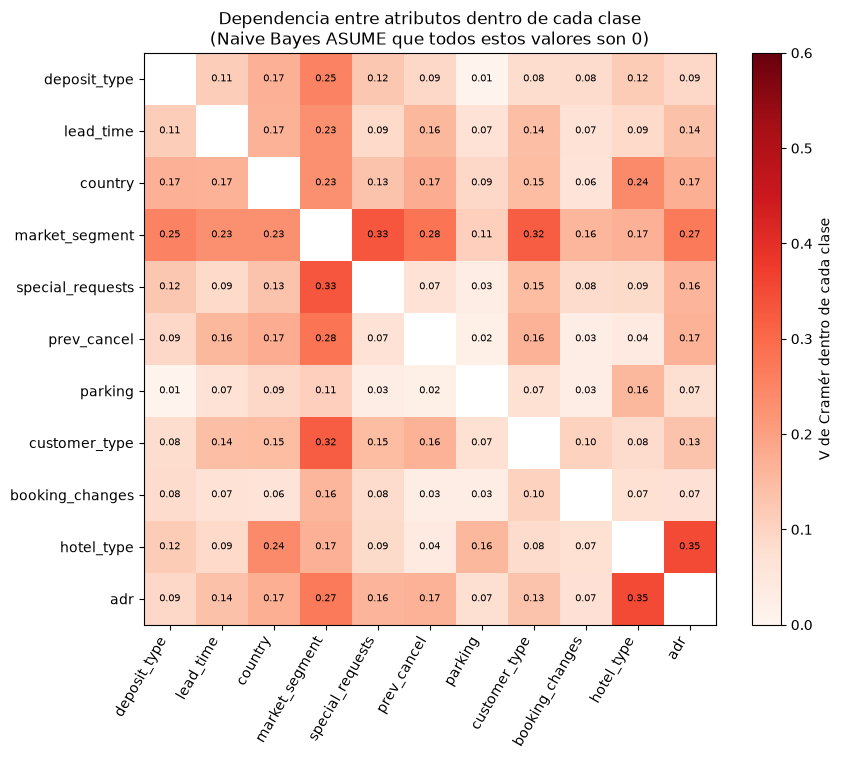

Pares de atributos MÁS dependientes entre sí (dentro de cada clase):


V_de_Cramer
hotel_type     adr                     0.351
market_segment special_requests        0.332
               customer_type           0.319
               prev_cancel             0.279
               adr                     0.268
deposit_type   market_segment          0.252
country        hotel_type              0.241
               market_segment          0.229

In [4]:
def discretize_for_bayes(Xp, yp, ref_X):
    """Versión discreta de 11 atributos clave (cortes fijos o aprendidos SOLO de ref_X = TRAIN)."""
    d = pd.DataFrame(index=Xp.index)
    d['is_canceled'] = yp.map({0: 'no', 1: 'si'})
    d['deposit_type'] = Xp['deposit_type']
    d['lead_time'] = pd.cut(Xp['lead_time'], bins=[-1, 7, 30, 90, 180, np.inf],
                            labels=['0-7d', '8-30d', '31-90d', '91-180d', '>180d']).astype(str)
    top_countries = ref_X['country'].value_counts().head(5).index
    d['country'] = np.where(Xp['country'].isin(top_countries), Xp['country'], 'Otro')
    d['market_segment'] = Xp['market_segment']
    d['special_requests'] = np.where(Xp['total_of_special_requests'] >= 2, '2+', Xp['total_of_special_requests'].astype(str))
    d['prev_cancel'] = np.where(Xp['previous_cancellations'] > 0, 'si', 'no')
    d['parking'] = np.where(Xp['required_car_parking_spaces'] > 0, 'si', 'no')
    d['customer_type'] = Xp['customer_type']
    d['booking_changes'] = np.where(Xp['booking_changes'] > 0, 'si', 'no')
    d['hotel_type'] = Xp['hotel_type']
    d['adr'] = pd.cut(Xp['adr'], bins=[-np.inf, 70, 100, 140, np.inf],
                      labels=['<=70', '70-100', '100-140', '>140']).astype(str)
    return d.astype(str)


bn_train = discretize_for_bayes(X_train, y_train, X_train)
bn_test = discretize_for_bayes(X_test, y_test, X_train)
attrs = [c for c in bn_train.columns if c != 'is_canceled']


def cramers_v(a, b):
    ct = pd.crosstab(a, b).to_numpy().astype(float)
    if min(ct.shape) < 2:
        return 0.0
    n = ct.sum(); exp = ct.sum(1, keepdims=True) @ ct.sum(0, keepdims=True) / n
    chi2 = ((ct - exp) ** 2 / exp).sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))


cond_v = pd.DataFrame(0.0, index=attrs, columns=attrs)
for cls, sub in bn_train.groupby('is_canceled'):
    w = len(sub) / len(bn_train)
    for i, a in enumerate(attrs):
        for b in attrs[i + 1:]:
            v = cramers_v(sub[a], sub[b]) * w
            cond_v.loc[a, b] += v; cond_v.loc[b, a] += v
_arr = cond_v.to_numpy(copy=True); np.fill_diagonal(_arr, np.nan)
cond_v = pd.DataFrame(_arr, index=attrs, columns=attrs)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cond_v.values, cmap='Reds', vmin=0, vmax=0.6)
ax.set_xticks(range(len(attrs))); ax.set_xticklabels(attrs, rotation=60, ha='right')
ax.set_yticks(range(len(attrs))); ax.set_yticklabels(attrs)
for i in range(len(attrs)):
    for j in range(len(attrs)):
        if i != j:
            ax.text(j, i, f'{cond_v.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, label='V de Cramér dentro de cada clase')
ax.set_title('Dependencia entre atributos dentro de cada clase\n(Naive Bayes ASUME que todos estos valores son 0)')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_01_dependencia_atributos.png', dpi=150, bbox_inches='tight'); plt.show()

pares = cond_v.where(np.triu(np.ones(cond_v.shape, dtype=bool), 1)).stack().dropna().sort_values(ascending=False)
print('Pares de atributos MÁS dependientes entre sí (dentro de cada clase):')
display(pares.head(8).round(3).rename('V_de_Cramer').to_frame())

**Lectura:** varios pares de atributos están claramente relacionados aun conociendo la clase (por ejemplo, el segmento de mercado con el tipo de cliente, el tipo de depósito o el hotel). La independencia que supone Naive Bayes, entonces, **no se cumple** en estos datos. La pregunta es cuánto le cuesta en desempeño: se responde comparándolo con la Red Bayesiana (sección 5), que sí modela estas dependencias.

In [5]:
class SafeOrdinalEncoder(BaseEstimator, TransformerMixin):
    """Codifica categorías como enteros 0..k-1 aprendidos en fit; una categoría
    nunca vista va al código reservado UNSEEN (CategoricalNB no acepta -1)."""
    UNSEEN = 63

    def fit(self, X, y=None):
        Xd = pd.DataFrame(X).astype(str)
        self.maps_ = [{v: i for i, v in enumerate(sorted(Xd[c].unique()))} for c in Xd.columns]
        return self

    def transform(self, X):
        Xd = pd.DataFrame(X).astype(str)
        return np.column_stack([Xd.iloc[:, j].map(m).fillna(self.UNSEEN).to_numpy(dtype=int)
                                for j, m in enumerate(self.maps_)])


other_cat = [c for c in categorical_cols if c != 'country']


def make_categorical_nb(n_bins=5, alpha=1.0):
    pre = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('bins', KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile',
                                                    subsample=None))]), numeric_cols),
        ('country', Pipeline([('bucket', TopCategoryBucketer(top_n=15)), ('ord', SafeOrdinalEncoder())]), ['country']),
        ('cat', SafeOrdinalEncoder(), other_cat),
    ])
    return Pipeline([('preprocessor', pre), ('model', CategoricalNB(alpha=alpha, min_categories=64))])


def make_gaussian_nb(var_smoothing=1e-9):
    return Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=True)),
                     ('model', GaussianNB(var_smoothing=var_smoothing))])


nb_rows = []
for vs in [1e-9, 1e-6, 1e-3, 1e-1]:
    s = cross_validate(make_gaussian_nb(vs), X_train, y_train, cv=cv5, scoring=SCORING, n_jobs=-1)
    nb_rows.append({'Variante': 'GaussianNB', 'Parametros': f'var_smoothing={vs:g}',
                    'F1_CV': s['test_f1'].mean(), 'Recall_CV': s['test_recall'].mean(),
                    'Precision_CV': s['test_precision'].mean(), 'Balanced_Acc_CV': s['test_balanced_accuracy'].mean(),
                    'ROC_AUC_CV': s['test_roc_auc'].mean(), 'params': ('gauss', vs)})
for n_bins in [5, 10]:
    for alpha in [0.5, 1.0]:
        s = cross_validate(make_categorical_nb(n_bins, alpha), X_train, y_train, cv=cv5, scoring=SCORING, n_jobs=-1)
        nb_rows.append({'Variante': 'CategoricalNB', 'Parametros': f'n_bins={n_bins}, alpha={alpha}',
                        'F1_CV': s['test_f1'].mean(), 'Recall_CV': s['test_recall'].mean(),
                        'Precision_CV': s['test_precision'].mean(), 'Balanced_Acc_CV': s['test_balanced_accuracy'].mean(),
                        'ROC_AUC_CV': s['test_roc_auc'].mean(), 'params': ('cat', n_bins, alpha)})

nb_cv = pd.DataFrame(nb_rows).sort_values('ROC_AUC_CV', ascending=False).reset_index(drop=True)
display(nb_cv.drop(columns='params').round(4))
nb_cv.drop(columns='params').to_csv(RESULTS_DIR / 'e2_tabla_01_naive_bayes_cv.csv', index=False)

,Variante,Parametros,F1_CV,Recall_CV,Precision_CV,Balanced_Acc_CV,ROC_AUC_CV
0,CategoricalNB,"n_bins=10, alpha=0.5",0.6436,0.5383,0.8002,0.7296,0.8315
1,CategoricalNB,"n_bins=10, alpha=1.0",0.6426,0.5360,0.8022,0.7291,0.8314
2,CategoricalNB,"n_bins=5, alpha=0.5",0.6322,0.5226,0.8001,0.7229,0.8260
3,CategoricalNB,"n_bins=5, alpha=1.0",0.6313,0.5201,0.8028,0.7225,0.8260
4,GaussianNB,var_smoothing=0.1,0.6201,0.8799,0.4787,0.6580,0.8090
5,GaussianNB,var_smoothing=0.001,0.6421,0.7966,0.5379,0.6969,0.8024
6,GaussianNB,var_smoothing=1e-09,0.6000,0.5063,0.7824,0.7034,0.8017
7,GaussianNB,var_smoothing=1e-06,0.6543,0.7304,0.5951,0.7171,0.8017


**Criterio de elección:** con umbral 0.5, Naive Bayes suele dar probabilidades muy extremas (cercanas a 0 o a 1, posiblemente por multiplicar como independientes atributos que comparten información), así que el F1 a 0.5 puede ser engañoso. Por eso se elige la variante por **ROC-AUC** (capacidad de ordenar las reservas por riesgo, independiente del umbral), y luego se le ajusta el umbral por CV como al resto de modelos.

Variante elegida: Naive Bayes Categórico (10 intervalos)
Umbral elegido por CV: 0.28 (F1 out-of-fold = 0.6869)


,Modelo,Entrega,Umbral,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,PR_AUC,fit_s,predict_s
0,Naive Bayes Categórico (10 intervalos),Entrega 2,0.28,0.758,0.7505,0.6579,0.7219,0.7792,0.6884,0.8308,0.7957,0.5483,0.1151


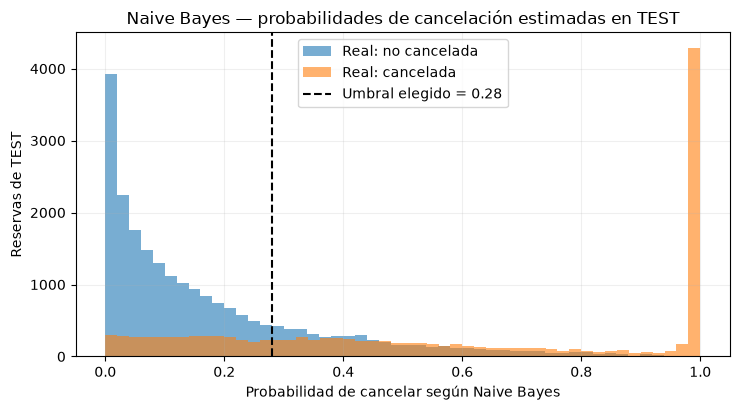

In [6]:
best_nb = nb_cv.iloc[0]['params']
if best_nb[0] == 'gauss':
    nb_model, nb_name = make_gaussian_nb(best_nb[1]), f'Naive Bayes Gaussiano (var_smoothing={best_nb[1]:g})'
else:
    nb_model, nb_name = make_categorical_nb(best_nb[1], best_nb[2]), f'Naive Bayes Categórico ({best_nb[1]} intervalos)'
print('Variante elegida:', nb_name)

oof_nb = cross_val_predict(nb_model, X_train, y_train, cv=cv5, method='predict_proba', n_jobs=-1)[:, 1]
thr_nb, f1_oof_nb = best_threshold(y_train, oof_nb, THRESHOLD_GRID)
print(f'Umbral elegido por CV: {thr_nb:.2f} (F1 out-of-fold = {f1_oof_nb:.4f})')

t0 = time.time(); nb_model.fit(X_train, y_train); fit_s = time.time() - t0
t0 = time.time(); scores_nb = nb_model.predict_proba(X_test)[:, 1]; pred_s = time.time() - t0
final_rows.append(evaluate(nb_name, 'Entrega 2', scores_nb, thr_nb, fit_s, pred_s))
test_scores[nb_name], test_thresholds[nb_name] = scores_nb, thr_nb
display(pd.DataFrame([final_rows[-1]]).round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.hist(scores_nb[y_test.to_numpy() == 0], bins=50, alpha=.6, label='Real: no cancelada')
ax.hist(scores_nb[y_test.to_numpy() == 1], bins=50, alpha=.6, label='Real: cancelada')
ax.axvline(thr_nb, color='black', linestyle='--', label=f'Umbral elegido = {thr_nb:.2f}')
ax.set_xlabel('Probabilidad de cancelar según Naive Bayes'); ax.set_ylabel('Reservas de TEST')
ax.set_title('Naive Bayes — probabilidades de cancelación estimadas en TEST')
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_02_naive_bayes_probabilidades.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Modelo nuevo 2 — Red Bayesiana (librería `pgmpy`)

**La diferencia con Naive Bayes.** Naive Bayes impone una estructura fija: la clase apunta a todos los atributos y ningún atributo se relaciona con otro. Una **Red Bayesiana** es un grafo dirigido en el que cada flecha `A → B` significa "B depende directamente de A". La librería **aprende ese grafo a partir de los datos**: responde a la pregunta de "qué atributos son dependientes con cuáles".

**Cómo se construye:**

1. **Estructura:** búsqueda *Hill Climbing* (agrega, quita o invierte flechas mientras mejore la puntuación **BIC**, que premia ajustar bien los datos pero castiga los grafos demasiado complejos).
2. **Parámetros:** para cada nodo, una tabla de probabilidades condicionales P(nodo | padres), estimada con un prior BDeu (suavizado para que ninguna combinación tenga probabilidad 0).
3. **Predicción:** la probabilidad de cancelar dada la reserva depende solo de su **manto de Markov** (padres, hijos y padres de los hijos de `is_canceled`).

Las redes bayesianas trabajan con variables discretas, así que se usan los 11 atributos discretizados de la sección 4.1. Para que la comparación sea justa, se entrena también **Naive Bayes sobre exactamente esos mismos 11 atributos**: la única diferencia entre ambos será la estructura (supuesta o aprendida).

In [7]:
def fit_bayesian_network(train_df):
    dag = HillClimbSearch(train_df).estimate(scoring_method='bic-d', max_indegree=3, show_progress=False)
    model = DiscreteBayesianNetwork(dag.edges())
    model.add_nodes_from(train_df.columns)
    states = {c: sorted(set(bn_train[c])) for c in train_df.columns}   # catálogo de categorías, solo de TRAIN
    cpds = BayesianEstimator(model, train_df, state_names=states).get_parameters(prior_type='BDeu', equivalent_sample_size=10)
    model.add_cpds(*cpds)
    return model


def bn_cancel_probability(model, data, target='is_canceled'):
    """P(is_canceled='si' | resto de atributos) exacta, usando el manto de Markov."""
    t_states = model.get_cpds(target).state_names[target]
    nodes = [target] + list(model.get_children(target))
    logp = np.zeros((len(data), len(t_states)))
    for k, s in enumerate(t_states):
        d = data.copy(); d[target] = s
        for n in nodes:
            cpd = model.get_cpds(n)
            idx = tuple(d[v].map({st: i for i, st in enumerate(cpd.state_names[v])}).to_numpy() for v in cpd.variables)
            logp[:, k] += np.log(cpd.values[idx])
    logp -= logp.max(axis=1, keepdims=True)
    p = np.exp(logp); p /= p.sum(axis=1, keepdims=True)
    return p[:, t_states.index('si')]


t0 = time.time(); bn_model = fit_bayesian_network(bn_train); bn_fit_s = time.time() - t0
edges = sorted(bn_model.edges())
print(f'Estructura aprendida en {bn_fit_s:.1f} s: {len(edges)} flechas entre {len(bn_model.nodes())} variables')
print('Padres de is_canceled (de qué depende directamente):', sorted(bn_model.get_parents('is_canceled')))
print('Hijos de is_canceled (qué cambia según si se cancela):', sorted(bn_model.get_children('is_canceled')))
print('Manto de Markov:', sorted(bn_model.get_markov_blanket('is_canceled')))
pd.DataFrame(edges, columns=['Desde', 'Hacia']).to_csv(RESULTS_DIR / 'e2_tabla_02_red_bayesiana_aristas.csv', index=False)

Estructura aprendida en 2.1 s: 30 flechas entre 12 variables
Padres de is_canceled (de qué depende directamente): ['country', 'deposit_type', 'market_segment']
Hijos de is_canceled (qué cambia según si se cancela): ['booking_changes', 'lead_time', 'parking', 'prev_cancel', 'special_requests']
Manto de Markov: ['booking_changes', 'country', 'customer_type', 'deposit_type', 'hotel_type', 'lead_time', 'market_segment', 'parking', 'prev_cancel', 'special_requests']


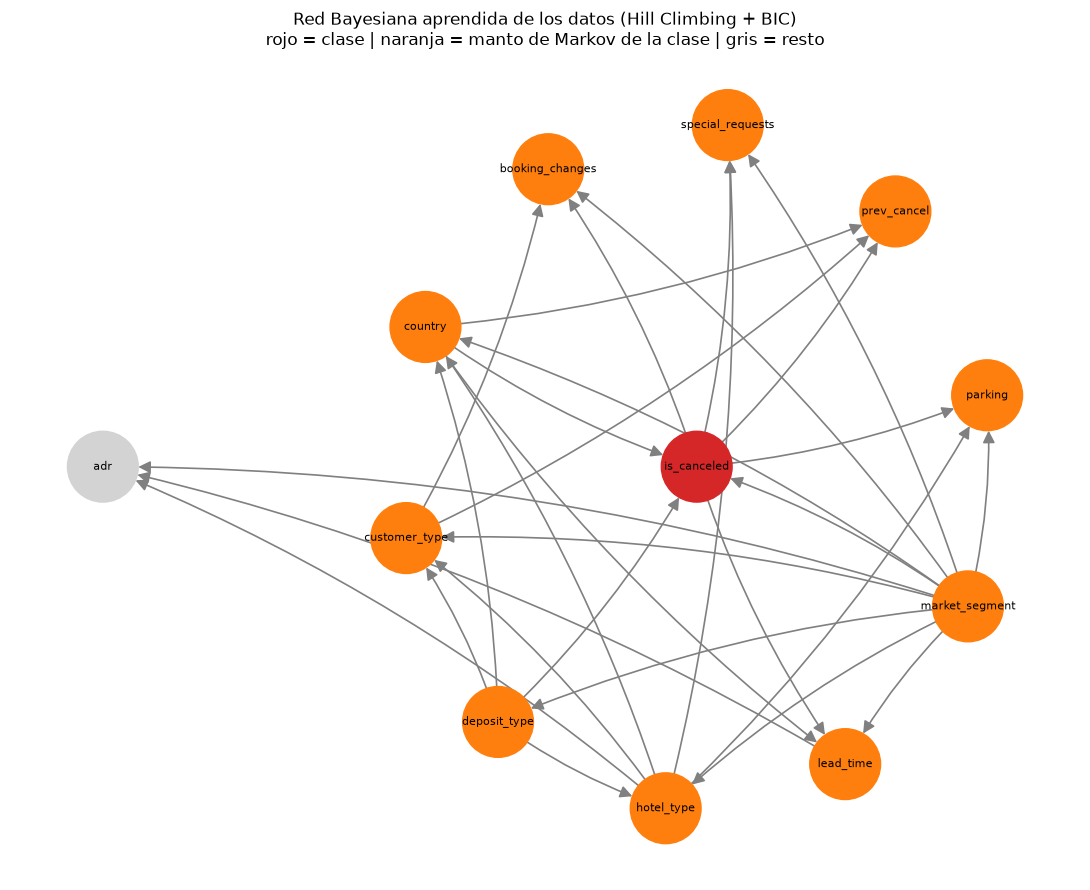

In [8]:
G = nx.DiGraph(bn_model.edges()); G.add_nodes_from(bn_model.nodes())
blanket = set(bn_model.get_markov_blanket('is_canceled'))
colors = ['tab:red' if n == 'is_canceled' else ('tab:orange' if n in blanket else 'lightgray') for n in G.nodes()]
pos = nx.shell_layout(G, nlist=[['is_canceled'], sorted(blanket), sorted(set(G.nodes()) - blanket - {'is_canceled'})])
fig, ax = plt.subplots(figsize=(11, 9))
nx.draw_networkx(G, pos, ax=ax, node_color=colors, node_size=2600, font_size=8, arrowsize=18,
                 edge_color='gray', width=1.2, connectionstyle='arc3,rad=0.08')
ax.set_title('Red Bayesiana aprendida de los datos (Hill Climbing + BIC)\n'
             'rojo = clase | naranja = manto de Markov de la clase | gris = resto')
ax.axis('off')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_03_red_bayesiana_grafo.png', dpi=150, bbox_inches='tight'); plt.show()

**Lo que permite una Red Bayesiana y Naive Bayes no:** hacer preguntas de probabilidad sobre cualquier combinación de variables, con **inferencia** (eliminación de variables). Algunos ejemplos con la red aprendida:

In [9]:
infer = VariableElimination(bn_model)
consultas = [
    ('Sin información (probabilidad base)', {}),
    ('Depósito no reembolsable', {'deposit_type': 'Non Refund'}),
    ('Sin depósito', {'deposit_type': 'No Deposit'}),
    ('Reservó con más de 180 días de anticipación', {'lead_time': '>180d'}),
    ('Pidió estacionamiento', {'parking': 'si'}),
    ('Hizo 2 o más solicitudes especiales', {'special_requests': '2+'}),
    ('Canceló antes otra reserva', {'prev_cancel': 'si'}),
    ('Agencia online + Portugal', {'market_segment': 'Online TA', 'country': 'PRT'}),
]
rows = []
for desc, ev in consultas:
    q = infer.query(['is_canceled'], evidence=ev, show_progress=False)
    rows.append({'Evidencia': desc, 'P(cancelar)': q.values[q.state_names['is_canceled'].index('si')]})
consultas_df = pd.DataFrame(rows)
display(consultas_df.round(3))
consultas_df.to_csv(RESULTS_DIR / 'e2_tabla_03_red_bayesiana_consultas.csv', index=False)

,Evidencia,P(cancelar)
0,Sin información (probabilidad base),0.370
1,Depósito no reembolsable,0.994
2,Sin depósito,0.283
3,Reservó con más de 180 días de anticipación,0.569
4,Pidió estacionamiento,0.000
5,Hizo 2 o más solicitudes especiales,0.208
6,Canceló antes otra reserva,0.919
7,Agencia online + Portugal,0.454


In [10]:
# Comparación justa: Red Bayesiana vs. Naive Bayes sobre los MISMOS 11 atributos discretizados.
# Para el umbral se usan predicciones out-of-fold: en cada fold se re-aprende la estructura y los parámetros.
def naive_bayes_same_vars():
    return Pipeline([('ord', SafeOrdinalEncoder()), ('model', CategoricalNB(alpha=1.0, min_categories=64))])


bn_X_train, bn_X_test = bn_train[attrs], bn_test[attrs]
oof_bn, oof_nb11 = np.zeros(len(bn_train)), np.zeros(len(bn_train))
for tr_idx, va_idx in cv5.split(bn_X_train, y_train):
    m = fit_bayesian_network(bn_train.iloc[tr_idx])
    oof_bn[va_idx] = bn_cancel_probability(m, bn_X_train.iloc[va_idx])
    nb11 = naive_bayes_same_vars().fit(bn_X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_nb11[va_idx] = nb11.predict_proba(bn_X_train.iloc[va_idx])[:, 1]

thr_bn, _ = best_threshold(y_train, oof_bn, THRESHOLD_GRID)
thr_nb11, _ = best_threshold(y_train, oof_nb11, THRESHOLD_GRID)

t0 = time.time(); scores_bn = bn_cancel_probability(bn_model, bn_X_test); bn_pred_s = time.time() - t0
nb11 = naive_bayes_same_vars()
t0 = time.time(); nb11.fit(bn_X_train, y_train); nb11_fit_s = time.time() - t0
t0 = time.time(); scores_nb11 = nb11.predict_proba(bn_X_test)[:, 1]; nb11_pred_s = time.time() - t0

bn_name = 'Red Bayesiana (11 atributos)'
row_bn = evaluate(bn_name, 'Entrega 2', scores_bn, thr_bn, bn_fit_s, bn_pred_s)
row_nb11 = evaluate('Naive Bayes (mismos 11 atributos)', 'Entrega 2', scores_nb11, thr_nb11, nb11_fit_s, nb11_pred_s)
final_rows.append(row_bn); test_scores[bn_name], test_thresholds[bn_name] = scores_bn, thr_bn

estructura = pd.DataFrame([row_nb11, row_bn])
estructura.insert(1, 'Estructura', ['Fija: independencia supuesta', f'Aprendida: {len(edges)} dependencias'])
display(estructura[['Modelo', 'Estructura', 'Umbral', 'F1', 'Recall', 'Precision', 'Balanced_Accuracy', 'ROC_AUC', 'PR_AUC']].round(4))
estructura.to_csv(RESULTS_DIR / 'e2_tabla_04_naive_bayes_vs_red_bayesiana.csv', index=False)

,Modelo,Estructura,Umbral,F1,Recall,Precision,Balanced_Accuracy,ROC_AUC,PR_AUC
0,Naive Bayes (mismos 11 atributos),Fija: independencia supuesta,0.27,0.7011,0.7293,0.6749,0.7613,0.8495,0.8130
1,Red Bayesiana (11 atributos),Aprendida: 30 dependencias,0.41,0.7531,0.7485,0.7578,0.8039,0.8993,0.8617


## 6. Modelo nuevo 3 — Máquina de Soporte Vectorial (SVM)

**Cómo funciona.** La SVM busca la frontera que separa las reservas canceladas de las no canceladas dejando el **mayor margen** (la franja vacía más ancha) entre ambas clases. Como las clases se solapan, se usa un **margen suave**: se permite que algunos puntos queden dentro del margen o del lado equivocado, con una penalización controlada por C. Los **vectores de soporte** son los puntos que quedan sobre el margen, dentro de él o mal clasificados: son los únicos que definen la frontera. Dos hiperparámetros clave:

- **Kernel:** `linear` (la frontera es un hiperplano) o `rbf` (la frontera puede curvarse, porque compara los puntos por similitud).
- **C:** cuánto se castigan los errores. C alto ajusta más los datos (riesgo de sobreajuste); C bajo prefiere un margen más ancho aunque cometa algunos errores.

Además se prueba `class_weight='balanced'` (mismo tratamiento del desbalance de la Entrega 1).

**Costo computacional:** entrenar una SVM con kernel cuesta entre el **cuadrado** y el **cubo** del número de filas, así que la rejilla se evalúa con CV sobre 8,000 filas de TRAIN. Si gana el kernel RBF, el modelo final se entrena con 30,000 filas de TRAIN (con las 83,573 completas no es viable). Si gana el lineal, `LinearSVC` usa el TRAIN completo.

La SVM no da probabilidades, sino una **puntuación con signo** (`decision_function`), proporcional a la distancia a la frontera: positiva significa "lado de cancelada". El umbral se ajusta sobre esa puntuación con el mismo criterio de F1 out-of-fold (sobre la muestra de 8,000 filas; al aplicarlo al modelo entrenado con 30,000 filas es una aproximación).

Tiempo de la búsqueda: 29.3 s


,Kernel,C,class_weight,F1_CV,F1_CV_std,Recall_CV,Precision_CV,ROC_AUC_CV,Tiempo_fit_s
0,rbf,1.00,balanced,0.7659,0.0116,0.7746,0.7578,0.8941,11.1168
1,rbf,10.00,None,0.7591,0.0080,0.7216,0.8009,0.8901,9.6945
2,rbf,10.00,balanced,0.7525,0.0082,0.7692,0.7367,0.8903,9.3536
3,rbf,1.00,None,0.7417,0.0157,0.6564,0.8524,0.8911,10.1530
4,lineal,0.01,balanced,0.7375,0.0102,0.7567,0.7195,0.8824,0.2186
5,lineal,0.10,balanced,0.7375,0.0097,0.7584,0.7179,0.8822,0.2494
6,lineal,1.00,balanced,0.7373,0.0095,0.7597,0.7164,0.8819,0.6690
7,rbf,0.10,balanced,0.7248,0.0127,0.7033,0.7485,0.8708,13.9645
8,lineal,0.10,None,0.7129,0.0128,0.6277,0.8252,0.8818,0.2797
9,lineal,1.00,None,0.7128,0.0129,0.6284,0.8238,0.8815,0.5408


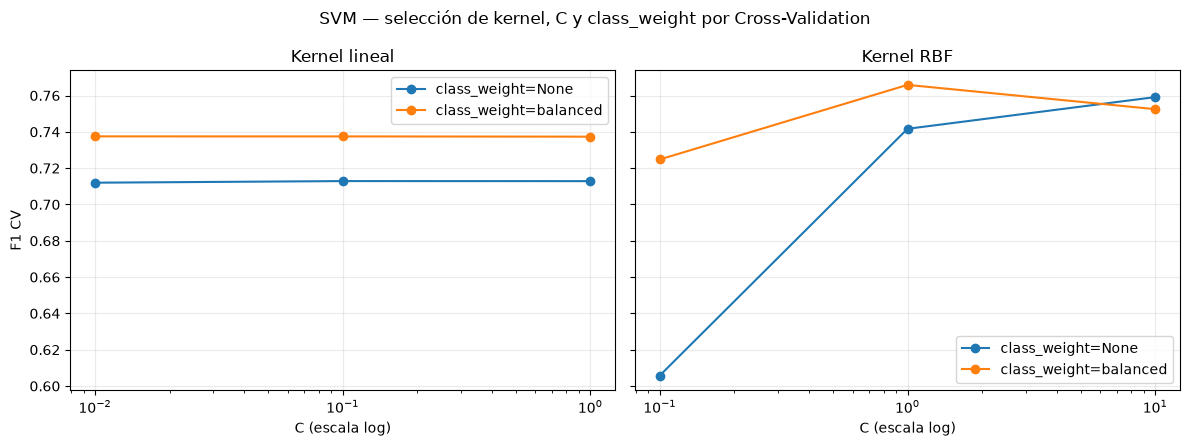

In [11]:
X_svm_cv, y_svm_cv = stratified_sample(X_train, y_train, SVM_TUNING_SAMPLE)
svm_pipe = Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=True)),
                     ('model', SVC())])
svm_grid = GridSearchCV(svm_pipe, param_grid=[
    {'model': [LinearSVC(dual='auto', max_iter=10000, random_state=RANDOM_STATE)],
     'model__C': [0.01, 0.1, 1], 'model__class_weight': [None, 'balanced']},
    {'model': [SVC(kernel='rbf', gamma='scale')],
     'model__C': [0.1, 1, 10], 'model__class_weight': [None, 'balanced']},
], scoring=SCORING, refit='f1', cv=cv5, n_jobs=-1)
t0 = time.time(); svm_grid.fit(X_svm_cv, y_svm_cv)
print(f'Tiempo de la búsqueda: {time.time()-t0:.1f} s')

svm_cv = pd.DataFrame(svm_grid.cv_results_)
svm_tab = pd.DataFrame({
    'Kernel': ['lineal' if isinstance(m, LinearSVC) else 'rbf' for m in svm_cv['param_model']],
    'C': svm_cv['param_model__C'], 'class_weight': [('balanced' if v == 'balanced' else 'None') for v in svm_cv['param_model__class_weight']],
    'F1_CV': svm_cv['mean_test_f1'], 'F1_CV_std': svm_cv['std_test_f1'],
    'Recall_CV': svm_cv['mean_test_recall'], 'Precision_CV': svm_cv['mean_test_precision'],
    'ROC_AUC_CV': svm_cv['mean_test_roc_auc'], 'Tiempo_fit_s': svm_cv['mean_fit_time'],
}).sort_values('F1_CV', ascending=False).reset_index(drop=True)
display(svm_tab.round(4))
svm_tab.to_csv(RESULTS_DIR / 'e2_tabla_05_svm_cv.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, kernel in zip(axes, ['lineal', 'rbf']):
    sub = svm_tab[svm_tab['Kernel'] == kernel]
    for cw, g in sub.groupby('class_weight'):
        g = g.sort_values('C')
        ax.plot(g['C'], g['F1_CV'], marker='o', label=f'class_weight={cw}')
    ax.set_xscale('log'); ax.set_xlabel('C (escala log)'); ax.set_title('Kernel lineal' if kernel == 'lineal' else 'Kernel RBF')
    ax.grid(alpha=.25); ax.legend()
axes[0].set_ylabel('F1 CV')
fig.suptitle('SVM — selección de kernel, C y class_weight por Cross-Validation')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_04_svm_cv.png', dpi=150, bbox_inches='tight'); plt.show()

In [12]:
best_svm = svm_grid.best_params_
is_linear = isinstance(best_svm['model'], LinearSVC)
if is_linear:
    svm_est = LinearSVC(C=best_svm['model__C'], class_weight=best_svm['model__class_weight'],
                        dual='auto', max_iter=10000, random_state=RANDOM_STATE)
    X_svm_fit, y_svm_fit = X_train, y_train
    svm_name = f"SVM lineal (C={best_svm['model__C']})"
else:
    svm_est = SVC(kernel='rbf', gamma='scale', C=best_svm['model__C'], class_weight=best_svm['model__class_weight'])
    X_svm_fit, y_svm_fit = stratified_sample(X_train, y_train, SVM_FINAL_SAMPLE)
    svm_name = f"SVM RBF (C={best_svm['model__C']})"


def make_svm():
    from sklearn.base import clone
    return Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=True)),
                     ('model', clone(svm_est))])


oof_svm = cross_val_predict(make_svm(), X_svm_cv, y_svm_cv, cv=cv5, method='decision_function', n_jobs=-1)
svm_thr_grid = np.quantile(oof_svm, np.linspace(0.05, 0.95, 181))
thr_svm, f1_oof_svm = best_threshold(y_svm_cv, oof_svm, svm_thr_grid)
print(f'{svm_name}: umbral sobre la distancia a la frontera = {thr_svm:+.3f} (F1 out-of-fold = {f1_oof_svm:.4f})')

print(f'Entrenando con {len(X_svm_fit):,} filas de TRAIN...')
svm_model = make_svm()
t0 = time.time(); svm_model.fit(X_svm_fit, y_svm_fit); fit_s = time.time() - t0
t0 = time.time(); scores_svm = svm_model.decision_function(X_test); pred_s = time.time() - t0
final_rows.append(evaluate(svm_name, 'Entrega 2', scores_svm, thr_svm, fit_s, pred_s))
test_scores[svm_name], test_thresholds[svm_name] = scores_svm, thr_svm
if not is_linear:
    print('Vectores de soporte:', int(svm_model.named_steps['model'].n_support_.sum()), f'de {len(X_svm_fit):,} filas de entrenamiento')
display(pd.DataFrame([final_rows[-1]]).round(4))

SVM RBF (C=1): umbral sobre la distancia a la frontera = +0.041 (F1 out-of-fold = 0.7668)
Entrenando con 30,000 filas de TRAIN...
Vectores de soporte: 13710 de 30,000 filas de entrenamiento


,Modelo,Entrega,Umbral,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,PR_AUC,fit_s,predict_s
0,SVM RBF (C=1),Entrega 2,0.0414,0.831,0.8208,0.7666,0.7817,0.86,0.7741,0.9056,0.8715,49.3321,25.1508


### 6.1 Cómo separa la SVM las reservas canceladas de las no canceladas

Para *ver* la idea de la SVM se usan **solo 2 variables reales** de Hotel Booking: `lead_time` (días entre la reserva y la llegada) y `adr` (tarifa diaria). Se toman 60 reservas de TRAIN (30 canceladas y 30 no canceladas) y se entrena una SVM lineal. Es solo una ilustración: **no cambia ningún resultado**, porque la SVM de la sección 6 se entrena con todas las variables.

- **Línea continua:** el hiperplano de decisión (distancia a la frontera = 0). De un lado la SVM predice *cancelada* (rojo) y del otro *no cancelada* (azul).
- **Líneas discontinuas:** los bordes del margen (distancia = ±1). La SVM busca la frontera con el margen más ancho.
- **Círculos negros:** los **vectores de soporte**, las reservas que definen la frontera.

**Lectura:** las reservas con poca anticipación tienden a no cancelarse y las de mucha anticipación a cancelarse (por eso la frontera es casi vertical en `lead_time`), pero las clases se **solapan mucho**. Por eso hay tantos vectores de soporte y por eso la SVM final necesita todas las variables (y, si gana RBF, una frontera curva).

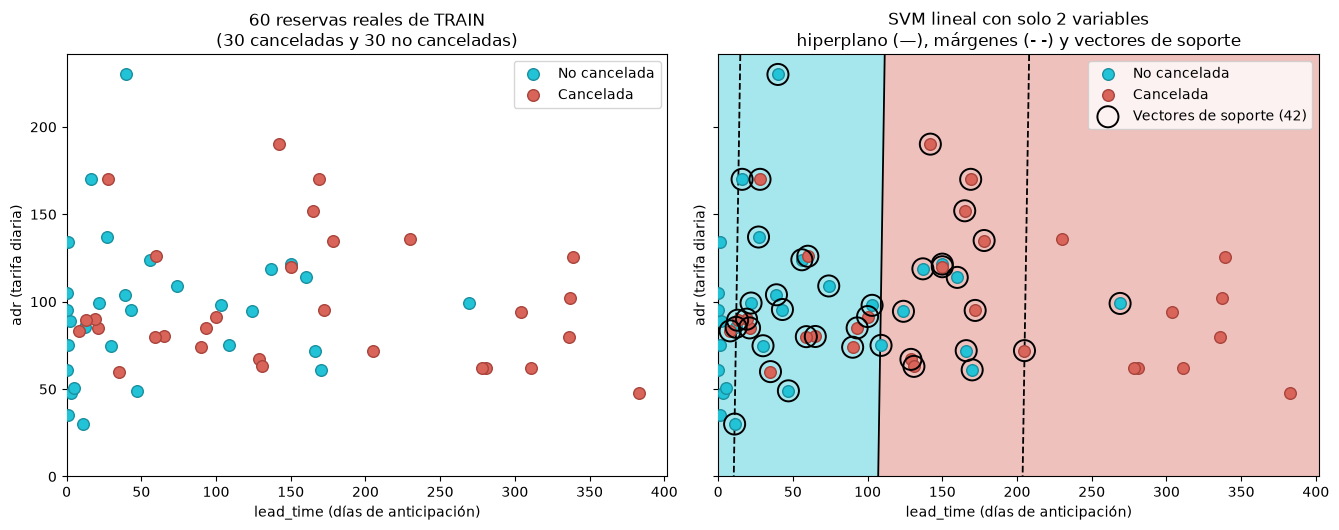

Con solo lead_time y adr las clases se solapan: la frontera falla en 33% de estas 60 reservas y 42 de 60 reservas quedan como vectores de soporte (dentro o sobre el margen).


In [13]:
# SVM sobre DOS variables reales de Hotel Booking (solo ilustración: la SVM de la sección 6 usa todas las variables)
from sklearn.pipeline import Pipeline as _Pipe
from sklearn.preprocessing import StandardScaler as _SS
from sklearn.svm import SVC as _SVC

_vx, _vy = 'lead_time', 'adr'                                  # anticipación de la reserva (días) y tarifa diaria
_lab = {_vx: 'lead_time (días de anticipación)', _vy: 'adr (tarifa diaria)'}
_ok = (X_train[_vy].between(1, 300)) & (X_train[_vx] <= 400)  # se omiten valores extremos solo para que el gráfico sea legible
_Xa, _ya = X_train.loc[_ok, [_vx, _vy]], y_train[_ok]
_idx = np.r_[_ya[_ya == 1].sample(30, random_state=RANDOM_STATE).index, _ya[_ya == 0].sample(30, random_state=RANDOM_STATE).index]
_P, _t = _Xa.loc[_idx].values, _ya.loc[_idx].values            # 60 reservas: 30 canceladas y 30 no canceladas

_m = _Pipe([('sc', _SS()), ('svm', _SVC(kernel='linear', C=1.0))]).fit(_P, _t)
_gx, _gy = np.meshgrid(np.linspace(0, _P[:, 0].max() * 1.05, 300), np.linspace(0, _P[:, 1].max() * 1.05, 300))
_z = _m.decision_function(np.c_[_gx.ravel(), _gy.ravel()]).reshape(_gx.shape)
_sv = _P[_m.named_steps['svm'].support_]

_cC, _cN = '#d9645a', '#22c3d6'                                 # rojo = cancelada, azul = no cancelada
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.4), sharex=True, sharey=True)
for ax in (ax1, ax2):
    ax.scatter(*_P[_t == 0].T, s=70, c=_cN, edgecolor='#1a8fa0', zorder=3, label='No cancelada')
    ax.scatter(*_P[_t == 1].T, s=70, c=_cC, edgecolor='#a8443b', zorder=3, label='Cancelada')
    ax.set_xlabel(_lab[_vx]); ax.set_ylabel(_lab[_vy])
ax1.legend(loc='upper right'); ax1.set_title('60 reservas reales de TRAIN\n(30 canceladas y 30 no canceladas)')
ax2.contourf(_gx, _gy, _z, levels=[-1e9, 0, 1e9], colors=[_cN, _cC], alpha=0.40, zorder=1)
ax2.contour(_gx, _gy, _z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=1.3, zorder=2)
ax2.scatter(*_sv.T, s=230, facecolors='none', edgecolors='k', linewidths=1.4, zorder=4, label=f'Vectores de soporte ({len(_sv)})')
ax2.legend(loc='upper right'); ax2.set_title('SVM lineal con solo 2 variables\nhiperplano (—), márgenes (- -) y vectores de soporte')
ax2.set_xlim(0, _P[:, 0].max() * 1.05); ax2.set_ylim(0, _P[:, 1].max() * 1.05)
plt.tight_layout(); plt.show()
_err = (_m.predict(_P) != _t).mean()
print(f'Con solo {_vx} y {_vy} las clases se solapan: la frontera falla en {_err:.0%} de estas 60 reservas '
      f'y {len(_sv)} de 60 reservas quedan como vectores de soporte (dentro o sobre el margen).')


### 6.2 ¿Alcanza una recta? Agregar dimensiones y el kernel

Izquierda: con 2 variables (`lead_time`, `adr`) las canceladas y no canceladas están mezcladas y la mejor recta separa poco. Derecha: se agrega una **tercera variable real**, `total_of_special_requests` (peticiones especiales del huésped), y un **hiperplano** (plano) en 3D separa mejor. Es la misma idea de las diapositivas: **más dimensiones dan más posibilidades de separar linealmente**. El **kernel RBF** logra algo parecido sin agregar columnas explícitas (*kernel trick*): equivale a una frontera curva en el espacio original.

La tabla compara, sobre una muestra del TEST, la **exactitud balanceada** (promedio del recall de cada clase, adecuada porque hay más no canceladas que canceladas). Las tres SVM de esta ilustración se entrenan con solo 3,000 reservas y 2 o 3 variables, por eso rinden mucho menos que la SVM completa de la sección 6.

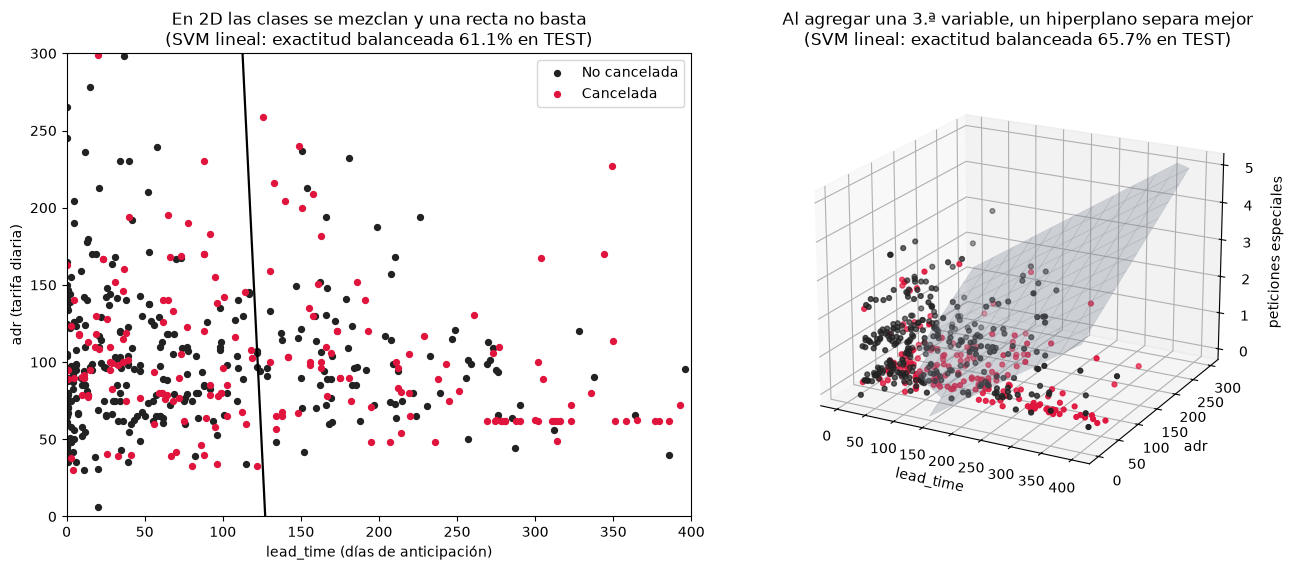

,Modelo,Exactitud balanceada (TEST)
0,2 variables · lineal,0.6106
1,2 variables · RBF,0.6295
2,3 variables · lineal,0.6574


In [14]:
# ¿Una recta alcanza? Se compara 2 variables (lineal y RBF) frente a 3 variables (lineal) con las reservas reales
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.metrics import balanced_accuracy_score as _bacc

_v3 = 'total_of_special_requests'                               # tercera variable: peticiones especiales del huésped
_cols2, _cols3 = [_vx, _vy], [_vx, _vy, _v3]
_n_fit = 3000                                                   # muestra estratificada de TRAIN (la SVM cuesta ~O(n^2))
_Xf, _yf = stratified_sample(X_train, y_train, _n_fit)
_Xt, _yt = stratified_sample(X_test, y_test, 6000)

def _fit(cols, kernel):
    return _Pipe([('sc', _SS()), ('svm', _SVC(kernel=kernel, C=1.0, class_weight='balanced'))]).fit(_Xf[cols], _yf)

_res = {}
for _name, _cols, _k in [('2 variables · lineal', _cols2, 'linear'), ('2 variables · RBF', _cols2, 'rbf'), ('3 variables · lineal', _cols3, 'linear')]:
    _mod = _fit(_cols, _k)
    _res[_name] = (_mod, _bacc(_yt, _mod.predict(_Xt[_cols])))

fig = plt.figure(figsize=(13.5, 5.8))
ax1 = fig.add_subplot(1, 2, 1)
_s = stratified_sample(X_train[_ok], y_train[_ok], 500); _S, _ys = _s
ax1.scatter(_S.loc[_ys == 0, _vx], _S.loc[_ys == 0, _vy], s=18, c='#222222', label='No cancelada')
ax1.scatter(_S.loc[_ys == 1, _vx], _S.loc[_ys == 1, _vy], s=18, c='#e0143c', label='Cancelada')
_m2 = _res['2 variables · lineal'][0]
_gx2, _gy2 = np.meshgrid(np.linspace(0, 400, 250), np.linspace(0, 300, 250))
ax1.contour(_gx2, _gy2, _m2.decision_function(pd.DataFrame(np.c_[_gx2.ravel(), _gy2.ravel()], columns=_cols2)).reshape(_gx2.shape),
            levels=[0], colors='k', linewidths=1.6)
ax1.set_xlabel(_lab[_vx]); ax1.set_ylabel(_lab[_vy]); ax1.legend(loc='upper right')
ax1.set_title(f'En 2D las clases se mezclan y una recta no basta\n(SVM lineal: exactitud balanceada {_res["2 variables · lineal"][1]:.1%} en TEST)')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
_rj = np.random.RandomState(0).uniform(-0.12, 0.12, len(_S))     # solo para que no se apilen los puntos discretos al graficar
_Z = _S[_v3].values + _rj
ax2.scatter(_S.loc[_ys == 0, _vx], _S.loc[_ys == 0, _vy], _Z[(_ys == 0).values], s=12, c='#222222')
ax2.scatter(_S.loc[_ys == 1, _vx], _S.loc[_ys == 1, _vy], _Z[(_ys == 1).values], s=12, c='#e0143c')
_m3 = _res['3 variables · lineal'][0]
_sc, _sv3 = _m3.named_steps['sc'], _m3.named_steps['svm']
_w, _b = _sv3.coef_[0] / _sc.scale_, _sv3.intercept_[0] - (_sv3.coef_[0] * _sc.mean_ / _sc.scale_).sum()   # plano en unidades originales
_px, _py = np.meshgrid(np.linspace(0, 400, 12), np.linspace(0, 300, 12))
_pz = -(_w[0] * _px + _w[1] * _py + _b) / _w[2]
_pz = np.where((_pz >= -0.3) & (_pz <= 5.3), _pz, np.nan)
ax2.plot_surface(_px, _py, _pz, alpha=0.30, color='#9aa5b8', edgecolor='#7b879b', linewidth=0.3)
ax2.set_xlabel('lead_time'); ax2.set_ylabel('adr'); ax2.set_zlabel('peticiones especiales'); ax2.set_zlim(-0.3, 5.3)
ax2.view_init(elev=20, azim=-62)
ax2.set_title(f'Al agregar una 3.ª variable, un hiperplano separa mejor\n(SVM lineal: exactitud balanceada {_res["3 variables · lineal"][1]:.1%} en TEST)')
plt.tight_layout(); plt.show()

display(pd.DataFrame({'Modelo': list(_res), 'Exactitud balanceada (TEST)': [round(v[1], 4) for v in _res.values()]}))


## 7. Modelo nuevo 4 — Red Neuronal Artificial (Perceptrón multicapa, `MLPClassifier`)

**Cómo funciona.** Cada neurona combina sus entradas con unos **pesos** (las **conexiones**), suma un sesgo y aplica una activación (ReLU). Las capas ocultas permiten aprender combinaciones no lineales de los atributos, y la última neurona entrega la probabilidad de cancelar (activación logística). Los pesos se ajustan con el optimizador Adam por retropropagación del error.

### 7.1 Las 3 redes de la entrega: una suave y dos que incrementan neuronas y capas ocultas

| Red | Capas ocultas | Neuronas por capa | Arquitectura |
|---|---|---|---|
| **Suave** | 1 | 16 | (16) |
| **Intermedia** | 2 | 64 | (64, 64) |
| **Grande** | 3 | 128 | (128, 128, 128) |

De una red a la siguiente aumentan **a la vez** las capas ocultas y las neuronas, así que el número de **conexiones** crece muy rápido. La pregunta es: **¿el modelo mejora al hacerlo más grande?**

Cada red se evalúa con validación cruzada de 5 folds sobre 20,000 filas de TRAIN (F1, ROC-AUC y su variabilidad), que también sirve para elegir su **umbral** con predicciones *out-of-fold* (mismo criterio de la Entrega 1). Después se entrena con el TRAIN completo y se evalúa **una vez** sobre TEST. Todas usan **early stopping** (se reserva el 10 % del entrenamiento y la red se detiene cuando deja de mejorar) para evitar el sobreajuste.

In [15]:
THREE_NETS = {
    'Red neuronal suave (16)': (16,),
    'Red neuronal intermedia (64, 64)': (64, 64),
    'Red neuronal grande (128, 128, 128)': (128, 128, 128),
}


def make_mlp(hidden):
    return Pipeline([('preprocessor', build_preprocessors(numeric_cols, categorical_cols, scale_numeric=True)),
                     ('model', MLPClassifier(hidden_layer_sizes=hidden, activation='relu', solver='adam',
                                             early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                                             max_iter=300, random_state=RANDOM_STATE))])


n_inputs = build_preprocessors(numeric_cols, categorical_cols, scale_numeric=True).fit(X_train).transform(X_train.head(1)).shape[1]
print('Entradas de la red (columnas tras One-Hot y escalado):', n_inputs)


def n_connections(hidden, n_in=n_inputs, n_out=1):
    sizes = [n_in] + list(hidden) + [n_out]
    return sum(a * b for a, b in zip(sizes[:-1], sizes[1:]))


def veredicto(f1_nuevo, f1_antes, tolerancia):
    d = f1_nuevo - f1_antes
    d = 0.0 if abs(d) < 0.00005 else d   # evita mostrar "-0.0000"
    if abs(d) <= tolerancia:
        return f'Quedó igual ({d:+.4f})'
    return f'Mejoró ({d:+.4f})' if d > 0 else f'Empeoró ({d:+.4f})'


X_mlp_cv, y_mlp_cv = stratified_sample(X_train, y_train, MLP_GRID_SAMPLE)
net_rows, trained_nets = [], {}
for name, hidden in THREE_NETS.items():
    s = cross_validate(make_mlp(hidden), X_mlp_cv, y_mlp_cv, cv=cv5, scoring=SCORING, n_jobs=-1)
    oof = cross_val_predict(make_mlp(hidden), X_mlp_cv, y_mlp_cv, cv=cv5, method='predict_proba', n_jobs=-1)[:, 1]
    thr, _ = best_threshold(y_mlp_cv, oof, THRESHOLD_GRID)
    model = make_mlp(hidden)
    t0 = time.time(); model.fit(X_train, y_train); fit_s = time.time() - t0
    t0 = time.time(); scores = model.predict_proba(X_test)[:, 1]; pred_s = time.time() - t0
    row = evaluate(name, 'Entrega 2', scores, thr, fit_s, pred_s)
    final_rows.append(row); test_scores[name], test_thresholds[name] = scores, thr; trained_nets[name] = model
    net_rows.append({'Red': name, 'Capas_ocultas': len(hidden), 'Neuronas_por_capa': hidden[0],
                     'Conexiones': n_connections(hidden),
                     'F1_CV': s['test_f1'].mean(), 'F1_CV_std': s['test_f1'].std(), 'ROC_AUC_CV': s['test_roc_auc'].mean(),
                     'Umbral': thr, 'F1_TEST': row['F1'], 'Balanced_Acc_TEST': row['Balanced_Accuracy'],
                     'ROC_AUC_TEST': row['ROC_AUC'], 'Epocas': model.named_steps['model'].n_iter_,
                     'Tiempo_entrenamiento_s': fit_s})
    print(f"{name:38s} conexiones={net_rows[-1]['Conexiones']:>6,}  F1 CV={net_rows[-1]['F1_CV']:.4f}  "
          f"F1 TEST={row['F1']:.4f}  ROC-AUC TEST={row['ROC_AUC']:.4f}  ({fit_s:.1f} s)")

tres_redes = pd.DataFrame(net_rows)
tol = tres_redes['F1_CV_std'].mean()
tres_redes['Respecto_a_la_red_anterior'] = ['— (punto de partida)'] + [
    veredicto(tres_redes.loc[i, 'F1_CV'], tres_redes.loc[i - 1, 'F1_CV'], tol) for i in range(1, len(tres_redes))]
print(f'\nCriterio: una diferencia de F1 CV menor que ±{tol:.4f} (desviación estándar media del CV) es "quedó igual".')
display(tres_redes.round(4))
tres_redes.to_csv(RESULTS_DIR / 'e2_tabla_06_tres_redes_neuronales.csv', index=False)

Entradas de la red (columnas tras One-Hot y escalado): 99
Red neuronal suave (16)                conexiones= 1,600  F1 CV=0.7517  F1 TEST=0.7779  ROC-AUC TEST=0.9173  (2.6 s)
Red neuronal intermedia (64, 64)       conexiones=10,496  F1 CV=0.7507  F1 TEST=0.7870  ROC-AUC TEST=0.9212  (5.4 s)
Red neuronal grande (128, 128, 128)    conexiones=45,568  F1 CV=0.7510  F1 TEST=0.7815  ROC-AUC TEST=0.9192  (13.0 s)

Criterio: una diferencia de F1 CV menor que ±0.0098 (desviación estándar media del CV) es "quedó igual".


,Red,Capas_ocultas,Neuronas_por_capa,Conexiones,F1_CV,F1_CV_std,ROC_AUC_CV,Umbral,F1_TEST,Balanced_Acc_TEST,ROC_AUC_TEST,Epocas,Tiempo_entrenamiento_s,Respecto_a_la_red_anterior
0,Red neuronal suave (16),1,16,1600,0.7517,0.0111,0.9069,0.38,0.7779,0.8250,0.9173,33,2.6341,— (punto de partida)
1,"Red neuronal intermedia (64, 64)",2,64,10496,0.7507,0.0044,0.9066,0.38,0.7870,0.8314,0.9212,22,5.3559,Quedó igual (-0.0010)
2,"Red neuronal grande (128, 128, 128)",3,128,45568,0.7510,0.0138,0.9076,0.34,0.7815,0.8272,0.9192,16,12.9821,Quedó igual (+0.0003)


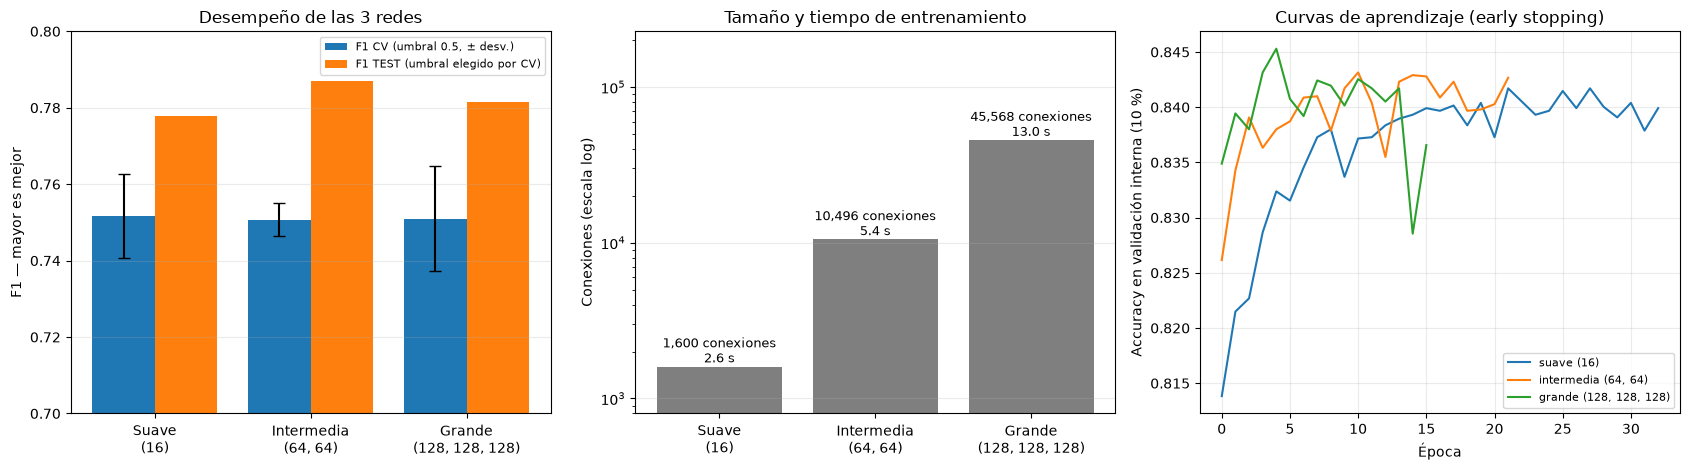

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
labels = ['Suave\n(16)', 'Intermedia\n(64, 64)', 'Grande\n(128, 128, 128)']
x = np.arange(len(tres_redes))
axes[0].bar(x - 0.2, tres_redes['F1_CV'], 0.4, yerr=tres_redes['F1_CV_std'], capsize=4, label='F1 CV (umbral 0.5, ± desv.)')
axes[0].bar(x + 0.2, tres_redes['F1_TEST'], 0.4, label='F1 TEST (umbral elegido por CV)')
axes[0].set_ylim(0.70, 0.80); axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel('F1 — mayor es mejor'); axes[0].set_title('Desempeño de las 3 redes'); axes[0].legend(fontsize=8); axes[0].grid(axis='y', alpha=.25)
axes[1].bar(x, tres_redes['Conexiones'], color='tab:gray')
for xi, (c, t) in enumerate(zip(tres_redes['Conexiones'], tres_redes['Tiempo_entrenamiento_s'])):
    axes[1].text(xi, c, f'{c:,} conexiones\n{t:.1f} s', ha='center', va='bottom', fontsize=9)
axes[1].set_yscale('log'); axes[1].set_ylim(tres_redes['Conexiones'].min() / 2, tres_redes['Conexiones'].max() * 5); axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_ylabel('Conexiones (escala log)'); axes[1].set_title('Tamaño y tiempo de entrenamiento'); axes[1].grid(axis='y', alpha=.25)
for name, model in trained_nets.items():
    axes[2].plot(model.named_steps['model'].validation_scores_, label=name.replace('Red neuronal ', ''))
axes[2].set_xlabel('Época'); axes[2].set_ylabel('Accuracy en validación interna (10 %)')
axes[2].set_title('Curvas de aprendizaje (early stopping)'); axes[2].grid(alpha=.25); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_05_tres_redes_neuronales.png', dpi=150, bbox_inches='tight'); plt.show()

### 7.2 Análisis complementario: separar el efecto de las capas y el de las neuronas

En las 3 redes de arriba cambian capas y neuronas al mismo tiempo, así que no se sabe cuál de los dos factores explica el resultado. Para separarlos, se prueban **todas las combinaciones** de 1, 2 y 3 capas con 16, 64 y 128 neuronas (9 redes, entre ellas las 3 anteriores), con la misma validación cruzada. Se compara cada red con la que tiene **una capa menos** (mismas neuronas) y con la que tiene **menos neuronas** (mismas capas).

,Arquitectura,Conexiones,F1_CV,F1_CV_std,ROC_AUC_CV,Tiempo_fit_medio_s,Al_agregar_una_capa,Al_aumentar_neuronas
0,"(16,)",1600,0.7517,0.0111,0.9069,0.7065,—,—
1,"(64,)",6400,0.7538,0.0126,0.9084,1.1315,—,Quedó igual (+0.0021)
2,"(128,)",12800,0.7574,0.0082,0.9102,1.9185,—,Quedó igual (+0.0036)
3,"(16, 16)",1856,0.7504,0.0106,0.9064,0.6823,Quedó igual (-0.0014),—
4,"(64, 64)",10496,0.7507,0.0044,0.9066,1.2207,Quedó igual (-0.0030),Quedó igual (+0.0004)
5,"(128, 128)",29184,0.7480,0.0131,0.9069,2.5649,Quedó igual (-0.0094),Quedó igual (-0.0027)
6,"(16, 16, 16)",2112,0.7546,0.0065,0.9066,0.8101,Quedó igual (+0.0042),—
7,"(64, 64, 64)",14592,0.7451,0.0073,0.9021,1.5755,Quedó igual (-0.0056),Quedó igual (-0.0094)
8,"(128, 128, 128)",45568,0.7510,0.0138,0.9076,3.6225,Quedó igual (+0.0030),Quedó igual (+0.0059)


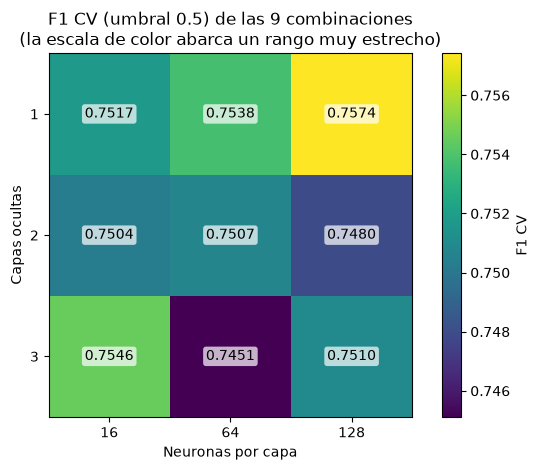

In [17]:
LAYERS, NEURONS = [1, 2, 3], [16, 64, 128]
mlp_rows = []
for n_layers in LAYERS:
    for n_neurons in NEURONS:
        hidden = tuple([n_neurons] * n_layers)
        s = cross_validate(make_mlp(hidden), X_mlp_cv, y_mlp_cv, cv=cv5, scoring=SCORING, n_jobs=-1)
        mlp_rows.append({'Capas': n_layers, 'Neuronas_por_capa': n_neurons, 'Arquitectura': str(hidden),
                         'Conexiones': n_connections(hidden),
                         'F1_CV': s['test_f1'].mean(), 'F1_CV_std': s['test_f1'].std(),
                         'ROC_AUC_CV': s['test_roc_auc'].mean(), 'Tiempo_fit_medio_s': s['fit_time'].mean()})
mlp_grid = pd.DataFrame(mlp_rows)
g = mlp_grid.set_index(['Capas', 'Neuronas_por_capa'])
tol_grid = mlp_grid['F1_CV_std'].mean()
vs_capas, vs_neuronas = [], []
for (cap, neu), r in g.iterrows():
    vs_capas.append('—' if cap == 1 else veredicto(r['F1_CV'], g.loc[(cap - 1, neu), 'F1_CV'], tol_grid))
    k = NEURONS.index(neu)
    vs_neuronas.append('—' if k == 0 else veredicto(r['F1_CV'], g.loc[(cap, NEURONS[k - 1]), 'F1_CV'], tol_grid))
mlp_grid['Al_agregar_una_capa'] = vs_capas
mlp_grid['Al_aumentar_neuronas'] = vs_neuronas
display(mlp_grid[['Arquitectura', 'Conexiones', 'F1_CV', 'F1_CV_std', 'ROC_AUC_CV', 'Tiempo_fit_medio_s',
                  'Al_agregar_una_capa', 'Al_aumentar_neuronas']].round(4))
mlp_grid.to_csv(RESULTS_DIR / 'e2_tabla_06b_red_neuronal_rejilla.csv', index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
heat = mlp_grid.pivot(index='Capas', columns='Neuronas_por_capa', values='F1_CV')
im = ax.imshow(heat.values, cmap='viridis')
ax.set_xticks(range(len(NEURONS))); ax.set_xticklabels(NEURONS)
ax.set_yticks(range(len(LAYERS))); ax.set_yticklabels(LAYERS)
ax.set_xlabel('Neuronas por capa'); ax.set_ylabel('Capas ocultas')
for i in range(len(LAYERS)):
    for j in range(len(NEURONS)):
        ax.text(j, i, f'{heat.values[i, j]:.4f}', ha='center', va='center', color='black', fontsize=10,
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))
ax.set_title('F1 CV (umbral 0.5) de las 9 combinaciones\n(la escala de color abarca un rango muy estrecho)')
plt.colorbar(im, ax=ax, label='F1 CV')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_06_red_neuronal_rejilla.png', dpi=150, bbox_inches='tight'); plt.show()

## 8. Comparación de todos los modelos sobre el mismo TEST

Cada modelo usa su propio umbral, elegido con validación cruzada dentro de TRAIN.

,Ranking_F1,Modelo,Entrega,Umbral,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,PR_AUC,fit_s,predict_s
0,1,Random Forest ajustado,Entrega 1,0.4900,0.8461,0.8379,0.7841,0.8064,0.8694,0.7951,0.9285,0.8983,29.5254,0.5028
1,2,"Red neuronal intermedia (64, 64)",Entrega 2,0.3800,0.8397,0.8314,0.7748,0.7997,0.8632,0.7870,0.9212,0.8901,5.3559,0.0639
2,3,"Red neuronal grande (128, 128, 128)",Entrega 2,0.3400,0.8341,0.8272,0.7632,0.8006,0.8538,0.7815,0.9192,0.8879,12.9821,0.0942
3,4,Red neuronal suave (16),Entrega 2,0.3800,0.8277,0.8250,0.7445,0.8144,0.8356,0.7779,0.9173,0.8853,2.6341,0.0573
4,5,SVM RBF (C=1),Entrega 2,0.0414,0.8310,0.8208,0.7666,0.7817,0.8600,0.7741,0.9056,0.8715,49.3321,25.1508
5,6,Árbol podado,Entrega 1,0.5800,0.8362,0.8172,0.7999,0.7438,0.8906,0.7708,0.9128,0.8692,2.7250,0.1802
6,7,KNN ajustado,Entrega 1,0.4300,0.8235,0.8086,0.7674,0.7512,0.8661,0.7592,0.9014,0.8696,0.5311,47.5031
7,8,Red Bayesiana (11 atributos),Entrega 2,0.4100,0.8182,0.8039,0.7578,0.7485,0.8592,0.7531,0.8993,0.8617,2.0938,0.3160
8,9,Naive Bayes Categórico (10 intervalos),Entrega 2,0.2800,0.7580,0.7505,0.6579,0.7219,0.7792,0.6884,0.8308,0.7957,0.5483,0.1151
9,—,Baseline (clase mayoritaria),Referencia,0.5000,0.6296,0.5000,0.0000,0.0000,1.0000,0.0000,0.5000,0.3704,0.0000,0.0000


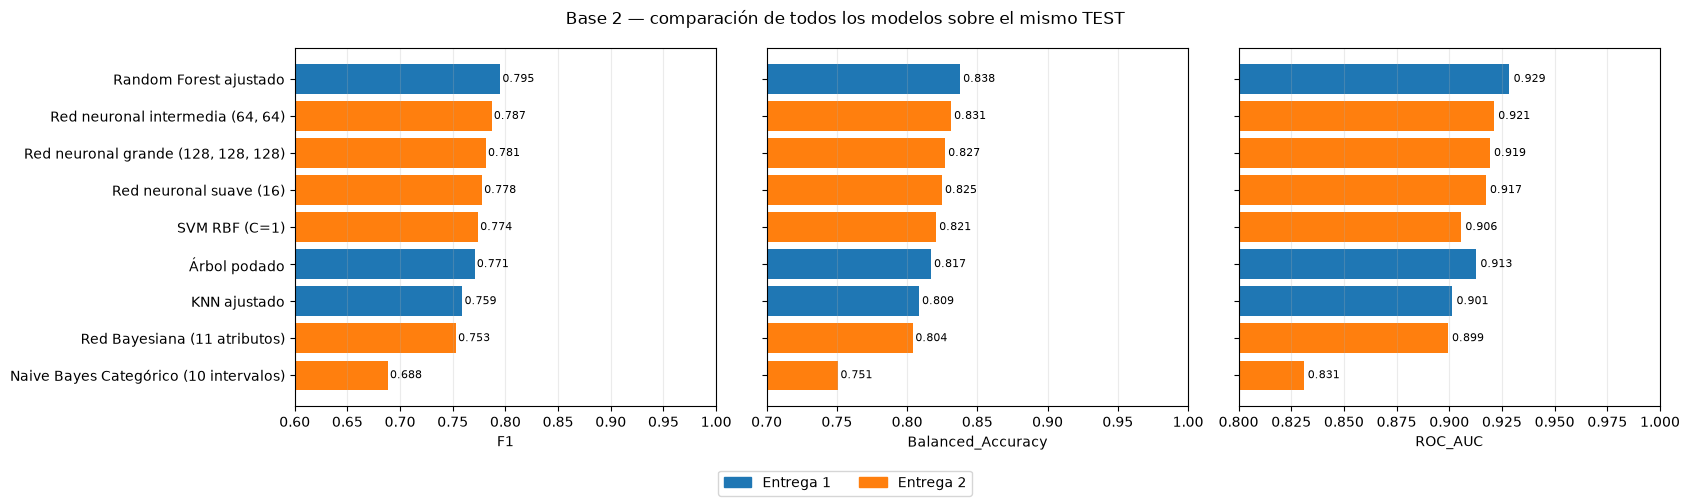

In [18]:
final_df = pd.DataFrame(final_rows)
order = final_df[final_df['Entrega'] != 'Referencia'].sort_values('F1', ascending=False)
final_df = pd.concat([order, final_df[final_df['Entrega'] == 'Referencia']]).reset_index(drop=True)
final_df.insert(0, 'Ranking_F1', list(range(1, len(order) + 1)) + ['—'])
cols = ['Ranking_F1', 'Modelo', 'Entrega', 'Umbral', 'Accuracy', 'Balanced_Accuracy', 'Precision', 'Recall',
        'Specificity', 'F1', 'ROC_AUC', 'PR_AUC', 'fit_s', 'predict_s']
display(final_df[cols].round(4))
final_df[cols].to_csv(RESULTS_DIR / 'e2_tabla_07_comparacion_final_test.csv', index=False)

plot_df = order.sort_values('F1')
colors = ['tab:orange' if e == 'Entrega 2' else 'tab:blue' for e in plot_df['Entrega']]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, metric, lo in zip(axes, ['F1', 'Balanced_Accuracy', 'ROC_AUC'], [0.6, 0.7, 0.8]):
    ax.barh(plot_df['Modelo'], plot_df[metric], color=colors)
    for yv, v in enumerate(plot_df[metric]):
        ax.text(v + 0.002, yv, f'{v:.3f}', va='center', fontsize=8)
    ax.set_xlim(lo, 1.0); ax.set_xlabel(metric); ax.grid(axis='x', alpha=.25)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='tab:blue', label='Entrega 1'), Patch(color='tab:orange', label='Entrega 2')],
           loc='lower center', ncol=2)
fig.suptitle('Base 2 — comparación de todos los modelos sobre el mismo TEST')
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.savefig(RESULTS_DIR / 'e2_fig_07_comparacion_final.png', dpi=150, bbox_inches='tight'); plt.show()

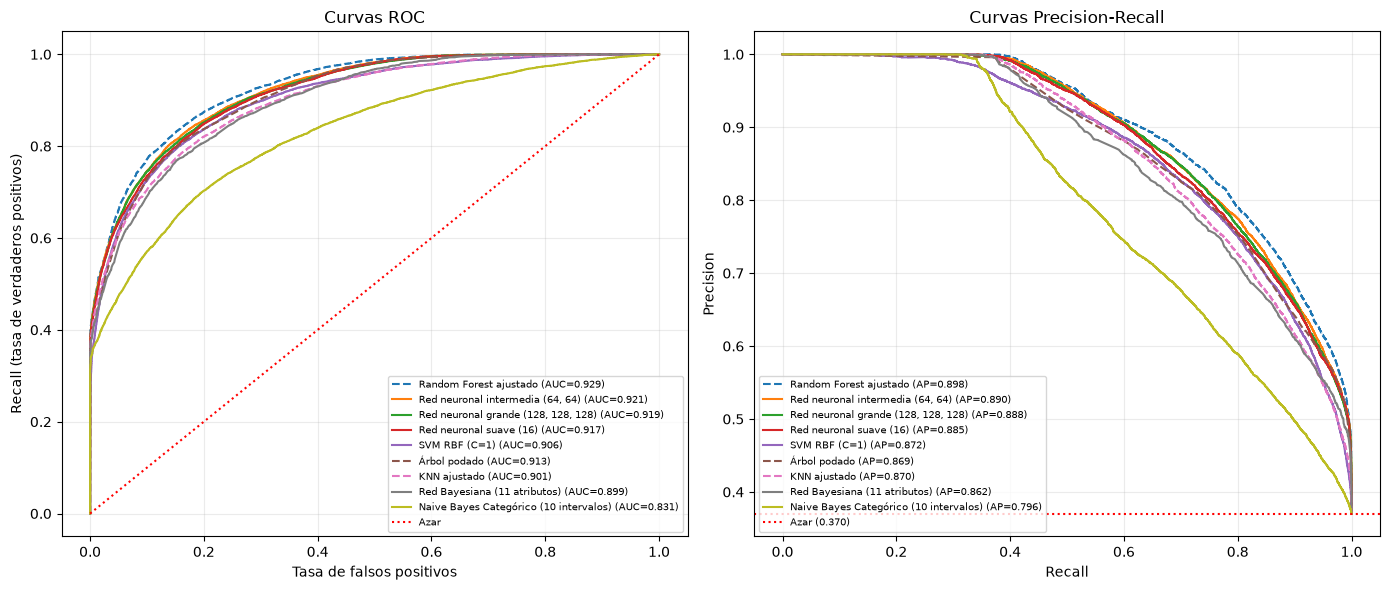

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in order['Modelo']:
    s = test_scores[name]
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    r = final_df.set_index('Modelo').loc[name]
    style = '-' if r['Entrega'] == 'Entrega 2' else '--'
    axes[0].plot(fpr, tpr, style, label=f"{name} (AUC={r['ROC_AUC']:.3f})")
    axes[1].plot(rec, prec, style, label=f"{name} (AP={r['PR_AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color='red', linestyle=':', label='Azar')
axes[0].set_xlabel('Tasa de falsos positivos'); axes[0].set_ylabel('Recall (tasa de verdaderos positivos)'); axes[0].set_title('Curvas ROC')
axes[1].axhline(y_test.mean(), color='red', linestyle=':', label=f'Azar ({y_test.mean():.3f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Curvas Precision-Recall')
for ax in axes: ax.grid(alpha=.25); ax.legend(fontsize=7, loc='lower left' if ax is axes[1] else 'lower right')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_08_roc_pr.png', dpi=150, bbox_inches='tight'); plt.show()

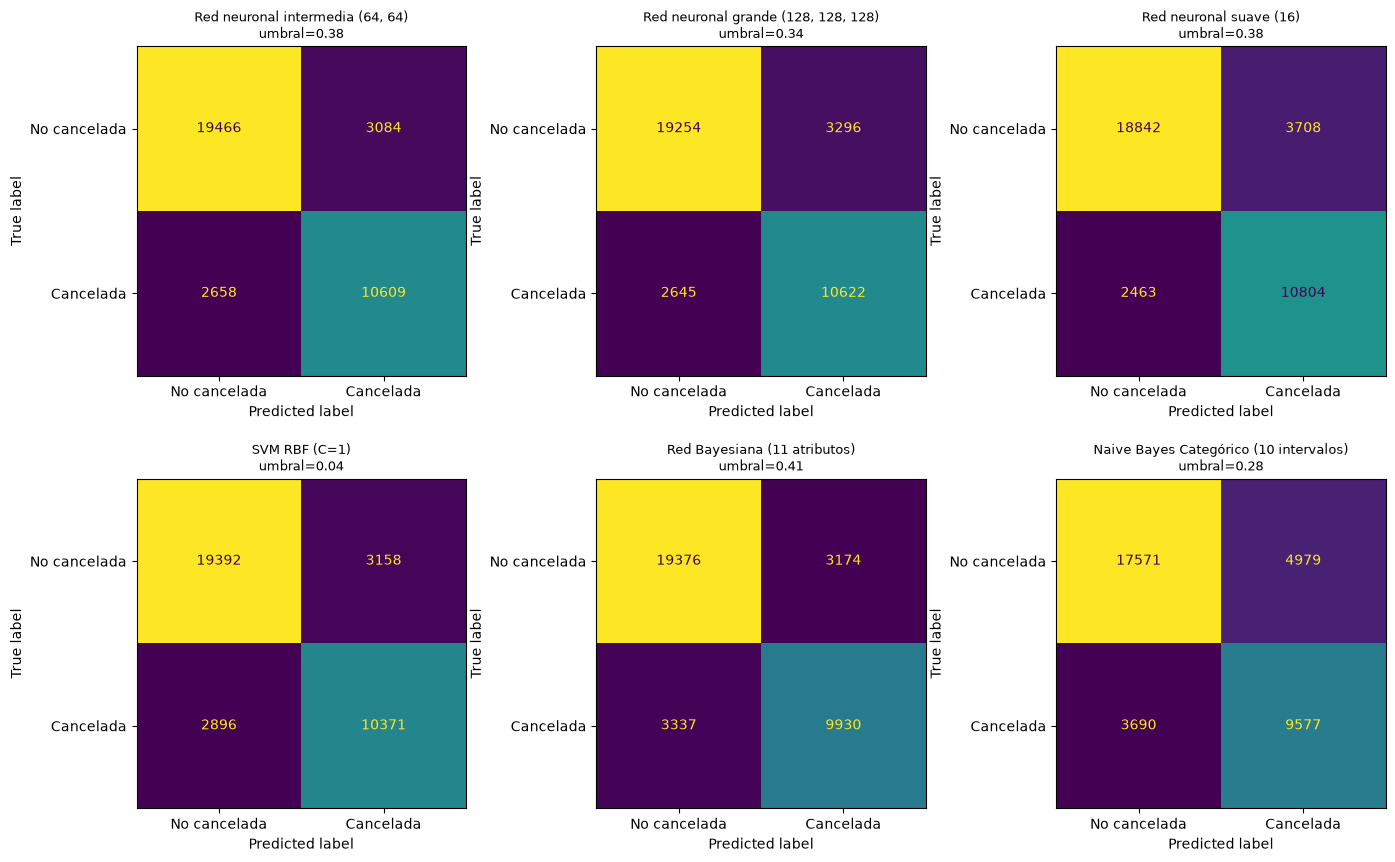

In [20]:
new_models = [m for m in order['Modelo'] if final_df.set_index('Modelo').loc[m, 'Entrega'] == 'Entrega 2']
n_cols = 3; n_rows_fig = int(np.ceil(len(new_models) / n_cols))
fig, axes = plt.subplots(n_rows_fig, n_cols, figsize=(14, 4.4 * n_rows_fig))
for ax in np.atleast_1d(axes).ravel()[len(new_models):]:
    ax.axis('off')
for ax, name in zip(np.atleast_1d(axes).ravel(), new_models):
    pred = (test_scores[name] >= test_thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['No cancelada', 'Cancelada']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(f'{name}\numbral={test_thresholds[name]:.2f}', fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_09_matrices_confusion_nuevos.png', dpi=150, bbox_inches='tight'); plt.show()

## 9. Conclusiones de la Entrega 2 (Base 2)

| Puesto (F1 en TEST) | Modelo | Entrega | F1 | Balanced Acc. | ROC-AUC |
|---|---|---|---|---|---|
| 1 | Random Forest (500 árboles) | 1 | 0.796 | 0.838 | 0.929 |
| 2 | **Red neuronal intermedia (64, 64)** | 2 | **0.787** | 0.831 | 0.921 |
| 3 | **Red neuronal grande (128, 128, 128)** | 2 | **0.782** | 0.827 | 0.919 |
| 4 | **Red neuronal suave (16)** | 2 | **0.778** | 0.825 | 0.917 |
| 5 | **SVM con kernel RBF (C=1)** | 2 | **0.774** | 0.821 | 0.906 |
| 6 | Árbol podado | 1 | 0.771 | 0.817 | 0.913 |
| 7 | KNN (K=30) | 1 | 0.759 | 0.809 | 0.901 |
| 8 | **Red Bayesiana (11 atributos)** | 2 | **0.753** | 0.804 | 0.899 |
| 9 | **Naive Bayes Categórico** | 2 | **0.688** | 0.751 | 0.831 |
| — | Baseline (clase mayoritaria) | — | 0.000 | 0.500 | 0.500 |

1. **Random Forest sigue siendo el mejor modelo**, pero las **3 redes neuronales** quedan muy cerca y, junto con la **SVM RBF**, superan al árbol y al KNN de la Entrega 1. Las redes además entrenan mucho más rápido que el Random Forest y predicen al instante.
2. **A diferencia de la regresión, aquí una frontera no lineal ayuda.** La SVM con kernel RBF supera a la lineal (F1 CV 0.766 frente a 0.738; ROC-AUC CV 0.894 frente a 0.882), y los modelos que capturan interacciones (bosques, redes neuronales) son los mejores. En la Base 1 pasó lo contrario: ganó el kernel lineal.
3. **Las 3 redes neuronales — ¿mejoró al hacerla más grande?**

   | Red | Conexiones | F1 CV (umbral 0.5, ± desv.) | ROC-AUC CV | F1 TEST |
   |---|---|---|---|---|
   | Suave (16) | 1,600 | 0.752 (± 0.011) | 0.907 | 0.778 |
   | Intermedia (64, 64) | 10,496 | 0.751 (± 0.004) | 0.907 | 0.787 |
   | Grande (128, 128, 128) | 45,568 | 0.751 (± 0.014) | 0.908 | 0.781 |

   En validación cruzada las tres **quedaron igual** (diferencias de una milésima, dentro del ruido de ± 0.0098). En TEST, la intermedia obtuvo +0.009 de F1 frente a la suave y la grande −0.006 frente a la intermedia, mientras el tiempo de entrenamiento aumentó varias veces. Esas diferencias en TEST son pequeñas y están dentro de la variación de la validación cruzada, así que no se puede afirmar que una red más grande sea mejor. Como la elección no debe hacerse mirando TEST, y en validación cruzada las tres empatan, se elige **la red suave** por ser la más simple (mismo criterio que en la Base 1). El análisis complementario de las 9 combinaciones confirma que ni agregar capas ni agregar neuronas cambia el resultado de forma consistente. Es la misma lección del árbol sin poda en la Entrega 1.
4. **Naive Bayes es el más débil.** Su suposición de independencia no se cumple: dentro de cada clase hay atributos claramente dependientes (V de Cramér de hasta 0.35 en los 11 atributos discretizados, por ejemplo tipo de hotel con tarifa, segmento de mercado con tipo de cliente o solicitudes especiales). Una explicación probable es que al tratar como independientes atributos que comparten información, sus probabilidades quedan mal calibradas, y por eso su umbral óptimo es tan bajo (0.28). Su ventaja: es de los modelos más rápidos y simples.
5. **La Red Bayesiana muestra el costo de esa suposición.** Con los mismos 11 atributos, pasar de la estructura supuesta (Naive Bayes) a la estructura aprendida de los datos (30 dependencias) sube el F1 de 0.701 a 0.753 y el ROC-AUC de 0.850 a 0.899. Con solo 11 variables discretizadas, la red bayesiana queda cerca del KNN, que usa las 28 variables. Además es el modelo más **interpretable**: la cancelación tiene como padres el **tipo de depósito**, el **segmento de mercado** y el **país**, y su manto de Markov incluye diez de los once atributos; solo la tarifa (`adr`) queda fuera (las flechas indican dependencias estadísticas, no causas). Las consultas muestran que la probabilidad de cancelar pasa de 37 % (base) a 99.4 % con depósito no reembolsable, a 91.9 % si el cliente ya canceló antes y a casi 0 % (0.05 %) si pidió estacionamiento.
6. **SVM:** casi la mitad de las filas de entrenamiento (13,710 de 30,000) terminaron como vectores de soporte, reflejo del solapamiento entre clases y del margen suave (C=1). Por eso la SVM es lenta para predecir (como el KNN) y no se entrenó con las 83,573 filas completas, lo que también la deja en ligera desventaja frente al resto.
7. **Recomendación:** si se busca el mejor desempeño, Random Forest; si se busca un equilibrio entre desempeño y velocidad, la red neuronal suave; si se necesita explicar el porqué y razonar con probabilidades ("¿qué pasa si el depósito es no reembolsable?"), la Red Bayesiana.